# 05. 소리 AI — '이 방의 평소 소리'를 배운 오토인코더

**문제:** 소음 부담을 "10분 급증 5→40회, 크기 250→600"처럼 사람이 정한 숫자로 계산하면, 교실마다 다른 배경 소리(환풍기, 복도 소리)와 소리의 종류를 반영하지 못한다.

**방법:** 사람 라벨 없이, 24시간 동안 기록한 10초 소리 특징 7개(크기·변동·최댓값·급증 횟수·말소리 대역 비율·스펙트럼 평탄도·스펙트럼 중심)로 **오토인코더**를 학습한다.
- 오토인코더는 입력을 3개 숫자로 압축했다가 다시 복원하도록 배운 신경망이다(7 → 8 → **3** → 8 → 7).
- 자주 들은 '평소 소리'는 잘 복원하고, 처음 듣는 종류의 소리는 복원 오차가 커진다.
- 이 **복원 오차**를 소음 부담으로 쓴다.

**평가:** 소리 종류별 주파수 특징 검증 실험 구간(11/14 13:50~13:54: 조용·말소리·쉬이이·휘파람·키보드)은 학습에서 빼고 평가에만 쓴다. 사람이 남긴 라벨(최적·산만)과도 비교한다.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from common import *

SND = ["snd_mean", "snd_std", "snd_max", "snd_spikes", "snd_sp", "snd_flat", "snd_cent"]
LOG = ["snd_mean", "snd_std", "snd_max", "snd_cent"]       # 크기 단위 값은 로그로 (큰 소리에 끌려가지 않게)

def transform(df):
    X = df[SND].astype(float).copy()
    for c in LOG: X[c] = np.log(X[c].clip(lower=1))
    X["snd_spikes"] = np.log1p(X["snd_spikes"])
    return X

d = pd.read_csv(f"{PROC}/records_clean.csv", encoding="utf-8-sig")
d["t"] = pd.to_datetime(d["time"]).dt.tz_convert("Asia/Seoul").dt.tz_localize(None)
d = d.dropna(subset=SND).reset_index(drop=True)
TEST = (d.t >= "2026-11-14 13:50:30") & (d.t <= "2026-11-14 13:53:40")
X = transform(d); tr = ~TEST.to_numpy()
print(f"학습 {tr.sum():,}개 (10초 기록) / 검증 실험 구간 {(~tr).sum()}개")

학습 8,418개 (10초 기록) / 검증 실험 구간 18개


## 학습

In [2]:
sc = StandardScaler().fit(X[tr]); Z = sc.transform(X)
ae = MLPRegressor(hidden_layer_sizes=(8, 3, 8), activation="relu", alpha=1e-3, max_iter=800,
                  early_stopping=True, random_state=0).fit(Z[tr], Z[tr])
err = ((ae.predict(Z) - Z) ** 2).mean(axis=1)
LO = float(np.percentile(err[tr], 90))          # 평소 소리의 90%가 이 오차 아래
HI = LO * 100                                   # 100배 크면 부담 1
def sound_burden(e): return np.clip(np.log10(np.maximum(e, 1e-9) / LO) / np.log10(HI / LO), 0, 1)
d["ae_err"] = err; d["s_snd_ai"] = sound_burden(err)
print(f"학습 데이터 복원 오차: 중앙값 {np.median(err[tr]):.4f}, 90% {LO:.4f} → 부담 0 기준, 부담 1 기준 {HI:.2f}")

학습 데이터 복원 오차: 중앙값 0.0056, 90% 0.0192 → 부담 0 기준, 부담 1 기준 1.92


## 검증 1 — 처음 듣는 소리 종류 (학습에서 뺀 실험 구간)

       소리  기록 수  복원 오차(최대)  소음 부담(최대)  기존 규칙 부담(최대)
       조용     3      0.064      0.263           1.0
      말소리     2      1.677      0.970           1.0
쉬이이(백색소음)     2      9.780      1.000           1.0
      휘파람     2      3.490      1.000           1.0
      키보드     3      8.539      1.000           1.0


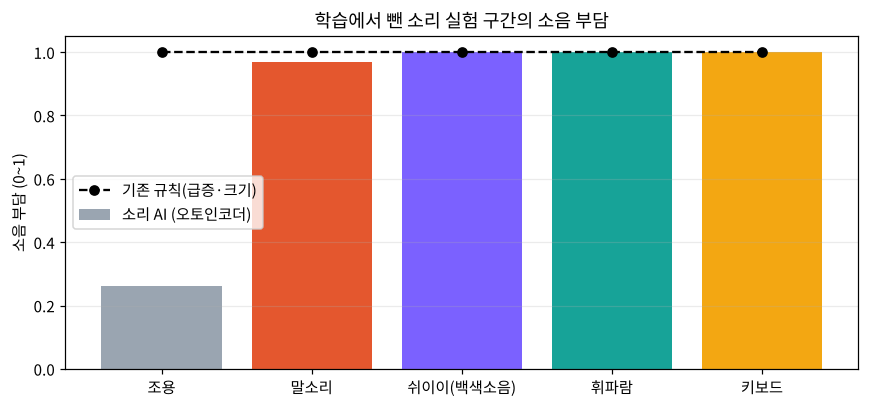

In [3]:
SEG = [("조용", "13:50:55", "13:51:24"), ("말소리", "13:51:24", "13:51:45"), ("쉬이이(백색소음)", "13:51:45", "13:52:07"),
       ("휘파람", "13:52:07", "13:52:27"), ("키보드", "13:52:27", "13:53:02")]
rows = []
for n, a, b in SEG:
    m = (d.t >= f"2026-11-14 {a}") & (d.t < f"2026-11-14 {b}")
    rows.append({"소리": n, "기록 수": int(m.sum()), "복원 오차(최대)": d.loc[m, "ae_err"].max(), "소음 부담(최대)": d.loc[m, "s_snd_ai"].max(),
                 "기존 규칙 부담(최대)": np.maximum(np.clip((d.loc[m, "f_snd_spikes"] - 5) / 35, 0, 1), np.clip((d.loc[m, "f_snd_mean"] - 250) / 350, 0, 1)).max()})
seg = pd.DataFrame(rows).round(3); print(seg.to_string(index=False))
seg.to_csv(f"{RES}/05_sound_ai_test.csv", index=False, encoding="utf-8-sig")

fig, a = plt.subplots(figsize=(8, 3.8))
cols = ["#9aa5b1", "#e4572e", "#7b61ff", "#17a398", "#f3a712"]
a.bar(seg["소리"], seg["소음 부담(최대)"], color=cols, label="소리 AI (오토인코더)")
a.plot(seg["소리"], seg["기존 규칙 부담(최대)"], "ko--", label="기존 규칙(급증·크기)")
a.set_ylim(0, 1.05); a.set_ylabel("소음 부담 (0~1)"); a.set_title("학습에서 뺀 소리 실험 구간의 소음 부담"); a.legend(); a.grid(alpha=.25, axis="y")
plt.tight_layout(); plt.savefig(f"{RES}/05_sound_ai_test.png", dpi=150); plt.show()

## 검증 2 — 사람이 남긴 라벨과 비교

In [4]:
L = d[d["state_label"].notna()]
y = (L["state_label"] == 2).astype(int)
rule = np.maximum(np.clip((L.f_snd_spikes - 5) / 35, 0, 1), np.clip((L.f_snd_mean - 250) / 350, 0, 1))
ai10 = L.groupby("seg")["s_snd_ai"].transform(lambda s: s.rolling(60, min_periods=1).mean())   # 장치처럼 최근 10분 평균
print(f"'산만' 구분력 AUC — 기존 규칙 {roc_auc_score(y, rule):.3f} / 소리 AI(10초) {roc_auc_score(y, L.s_snd_ai):.3f} / 소리 AI(10분 평균) {roc_auc_score(y, ai10):.3f}")
print(L.groupby("group").agg(상태=("state_label", lambda s: STATE_KO[int(s.iloc[0])]), 평균오차=("ae_err", "mean"), 소리AI부담=("s_snd_ai", "mean")).round(3).to_string())

'산만' 구분력 AUC — 기존 규칙 0.673 / 소리 AI(10초) 0.641 / 소리 AI(10분 평균) 0.785
       상태   평균오차  소리AI부담
group                   
0      산만  0.572   0.393
1      산만  0.122   0.248
2      산만  0.269   0.211
3      최적  0.122   0.183
4      최적  0.090   0.103
5      최적  0.024   0.030
6      최적  0.018   0.033
7      최적  0.020   0.040
8      산만  0.041   0.037


## 저장 (장치용 변환은 06번)

In [5]:
joblib.dump({"model": ae, "scaler": sc, "feats": SND, "log": LOG, "LO": LO, "HI": HI}, f"{PROC}/sound_ae.joblib")
d[["time", "ae_err", "s_snd_ai"]].to_csv(f"{PROC}/sound_ai.csv", index=False, encoding="utf-8-sig")
print("저장 완료")

저장 완료
